<a href="https://colab.research.google.com/github/nabipay/Auto-MPG-PCA-KMeans/blob/main/Aut0_MPG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Objective**
The objective of this problem is to explore the data, reduce the number of features by using PCA and extract meaningful insights.

**Data Dictionary**
The data has the following attributes:

 * mpg: miles per gallon
 * cyl: number of cylinders
 * disp: engine displacement (cu. inches) or * engine size
 * hp: horsepower
 * wt: vehicle weight (lbs.)
 * acc: time taken to accelerate from O to 60 mph (sec.)
 * yr: model year
 * car name: car model name

# **Importing Data**

In [5]:
# import python libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Plot settings
sns.set_theme(style='whitegrid')

In [6]:
# import dataset
df = pd.read_csv('/content/auto-mpg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,car name
0,18.0,8,307.0,130,3504,12.0,70,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,ford torino


In [7]:
# first glance of basic statistics of data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   car name      398 non-null    object 
dtypes: float64(3), int64(3), object(2)
memory usage: 25.0+ KB


'car name' and 'horsepower' are listed categorical.

In [8]:
# lets investigate why horsepower listed as object

df['horsepower'].unique()

array(['130', '165', '150', '140', '198', '220', '215', '225', '190',
       '170', '160', '95', '97', '85', '88', '46', '87', '90', '113',
       '200', '210', '193', '?', '100', '105', '175', '153', '180', '110',
       '72', '86', '70', '76', '65', '69', '60', '80', '54', '208', '155',
       '112', '92', '145', '137', '158', '167', '94', '107', '230', '49',
       '75', '91', '122', '67', '83', '78', '52', '61', '93', '148',
       '129', '96', '71', '98', '115', '53', '81', '79', '120', '152',
       '102', '108', '68', '58', '149', '89', '63', '48', '66', '139',
       '103', '125', '133', '138', '135', '142', '77', '62', '132', '84',
       '64', '74', '116', '82'], dtype=object)

one entry is '?'

In [9]:
(df['horsepower'] == '?').sum()

np.int64(6)

there are 6 entry of horsepower that have missing value filled as '?'

In [10]:
# replace horsepower '?' value with its mean
df['horsepower'] = df['horsepower'].replace('?', np.nan)
df['horsepower'] = df['horsepower'].astype(float)
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].mean())

In [11]:
df.head(5)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,car name
0,18.0,8,307.0,130.0,3504,12.0,70,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,ford torino


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   car name      398 non-null    object 
dtypes: float64(4), int64(3), object(1)
memory usage: 25.0+ KB


In [13]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.199187,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,76.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,95.000000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


* there are 398 observation with zero missing values.
* average mpg is about 24 mpg.
* average cylinder is 5 and maximum cylinder is 8.
* All cars are below 6000 lbs and avergae weight is about 3000 lb.
* The fastest car takes 8 sec to geos from 0 to 60.

In [14]:
# lets investigate the data type of clylinder and model year
df['cylinders'].unique()

array([8, 4, 6, 3, 5])

In [15]:
df['model year'].unique()

array([70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82])

In [16]:
df['model year'].value_counts()

,count
model year,
73,40
78,36
76,34
82,31
75,30
80,29
79,29
81,29
70,29


most cares are made in 73.

In [17]:
# change cylinder and model year data type to object
df['cylinders'] = df['cylinders'].astype(object)
df['model year'] = df['model year'].astype(object)

In [18]:
# identify numeric and categorical variable
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

In [19]:
num_cols

['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']

In [20]:
cat_cols

['cylinders', 'model year', 'car name']

In [21]:
# identify missing values
df.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model year,0
car name,0


There are no missing values.

In [22]:
# check for duplicates
df.duplicated().sum()

np.int64(0)

there is no duplicated row

# **Univarite Analysis**

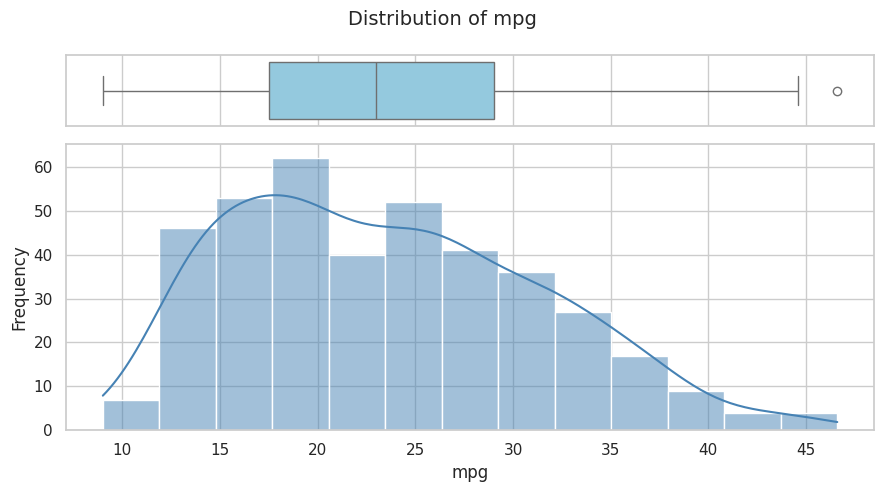

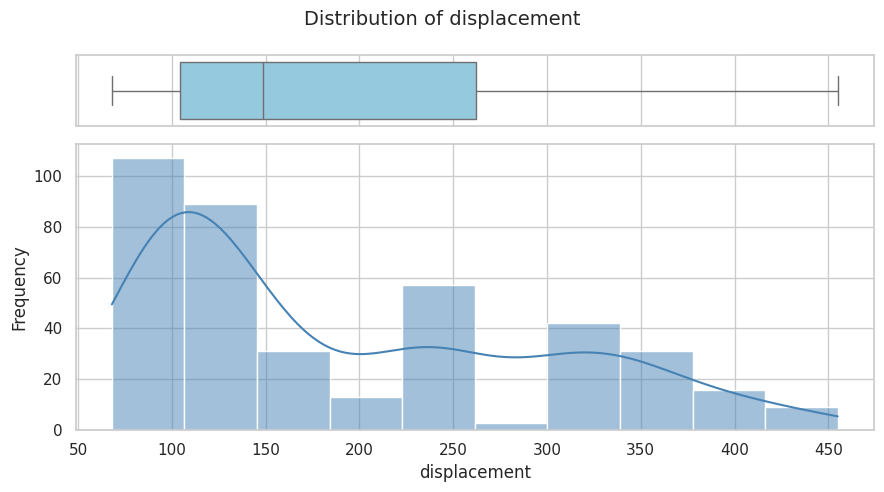

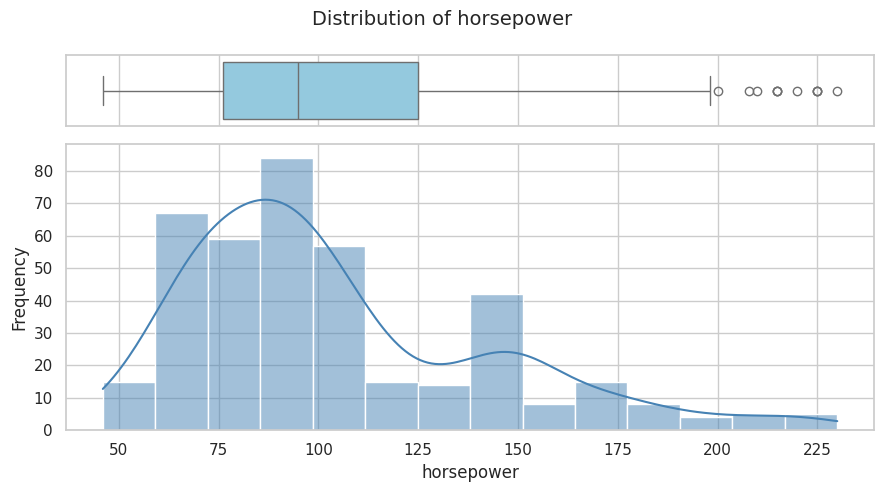

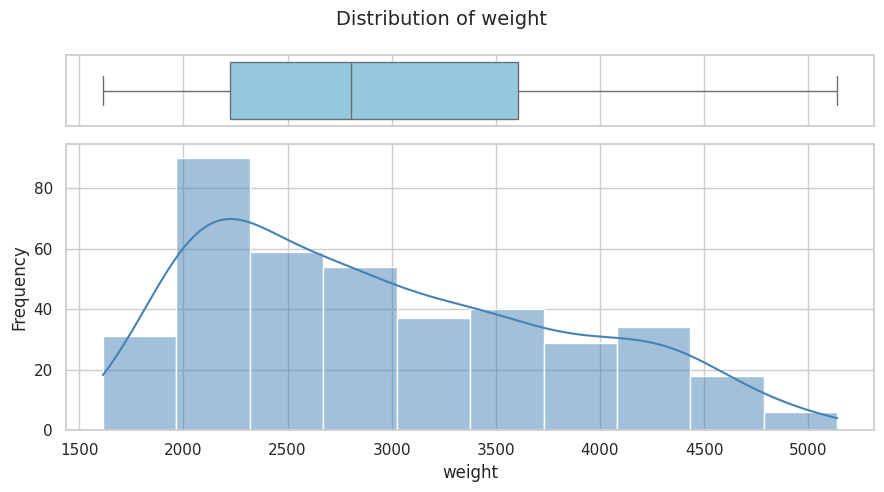

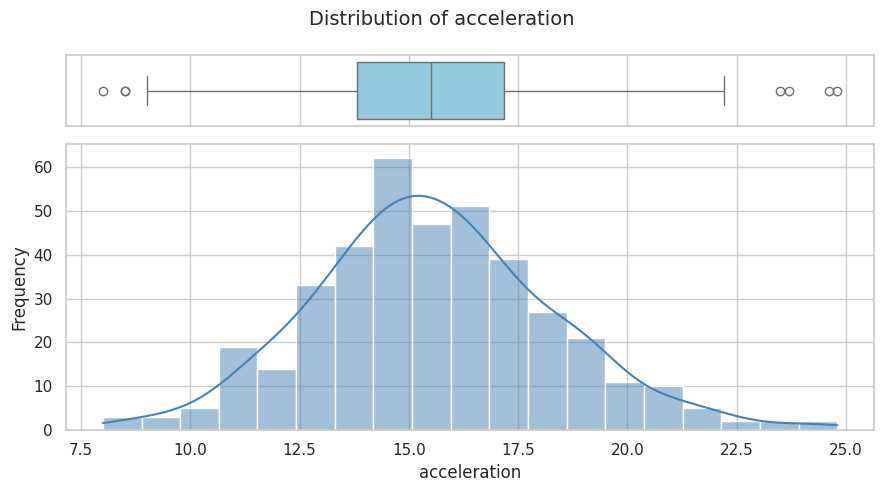

In [23]:

def numerical_plots(df):
    num_cols = df.select_dtypes(include=np.number).columns

    for col in num_cols:
        fig, axes = plt.subplots(
            2, 1,
            figsize=(9, 5),
            sharex=True,
            gridspec_kw={'height_ratios': [1, 4]}
        )

        sns.boxplot(data=df, x=col, ax=axes[0], color='skyblue')
        sns.histplot(data=df, x=col, kde=True,
                     ax=axes[1], color='steelblue')

        axes[0].set(xlabel='', ylabel='')
        axes[1].set_ylabel('Frequency')
        fig.suptitle(f'Distribution of {col}', fontsize=14)

        plt.tight_layout()
        plt.show()

numerical_plots(df)


* the distribution of mpg seems approximately symmetric
* the distribution of displacemetn is bimodal
* the distribution of horsepower and weight is skewed to the right
* the distribution of acceleration is normal


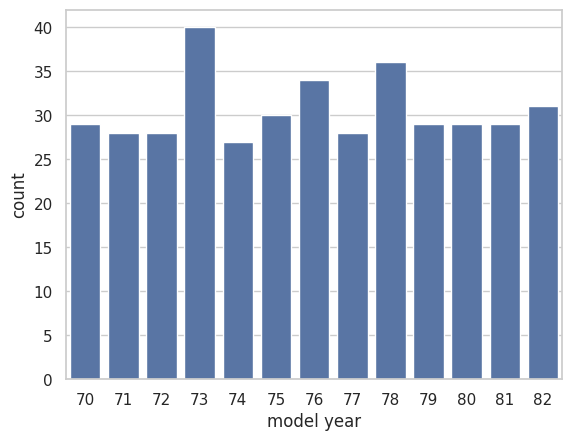

In [24]:
# count plot of model year
sns.countplot(
    data = df,
    x = 'model year'
)
plt.show()

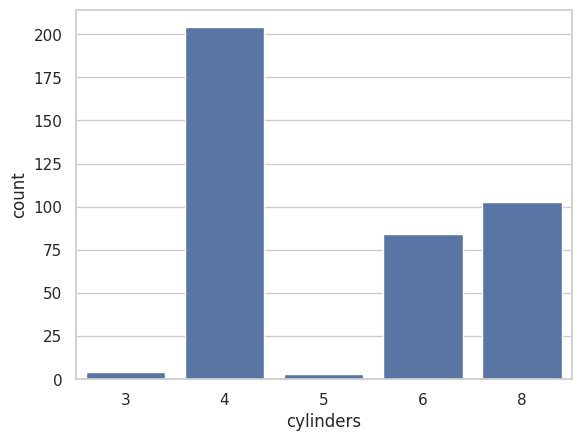

In [25]:
# count plot of cylinder
sns.countplot(
    data = df,
    x = 'cylinders'
)
plt.show()

there are about slightly more than 200 cars with 4 cylinders but only about 70 to 100 cars with 6 or 8 cylinders

# **Bivariate Analysis**

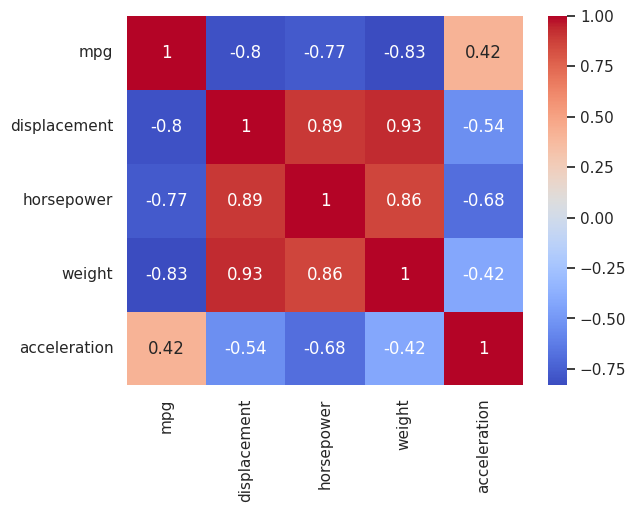

In [26]:
# correlation matrix of numerical columns
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

this results suggests that
* weight has a storongest negative correlation to mpg followed by displacement
* acceleration has a moderate positive correlation to mpg
* weight and displacement have strong positive correlation
* weight and horespower have positive correlation

# **PCA Analysis**

In [27]:
# import library
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [28]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[num_cols])

In [29]:
np.mean(scaled_data, axis=0)

array([ 7.14113302e-17, -1.78528326e-17,  1.78528326e-16, -1.60675493e-16,
       -2.67792488e-16])

In [30]:
np.std(scaled_data, axis=0)

array([1., 1., 1., 1., 1.])

In [31]:
from sklearn.decomposition import PCA

In [32]:
pca = PCA()
pca.fit(scaled_data)

PCA()

In [33]:
pca.explained_variance_ratio_

array([0.7834433 , 0.14260338, 0.04546783, 0.01780513, 0.01068035])

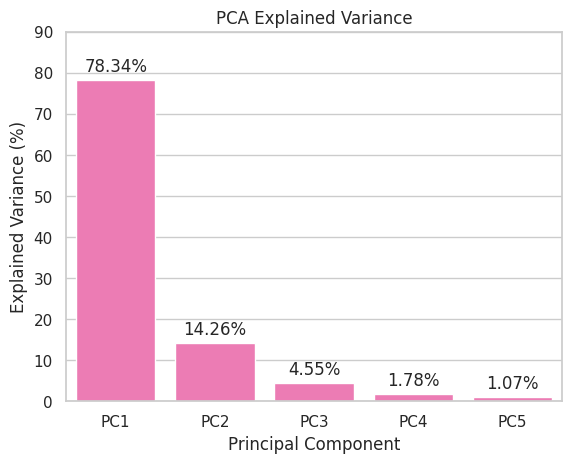

In [34]:
# explained variance of each principal component
explained_variance = pca.explained_variance_ratio_ * 100

ax = sns.barplot(
    x=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'],
    y=explained_variance,
    color='hotpink'
)

ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3)

plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title('PCA Explained Variance')
plt.ylim(0, 90)
plt.show()

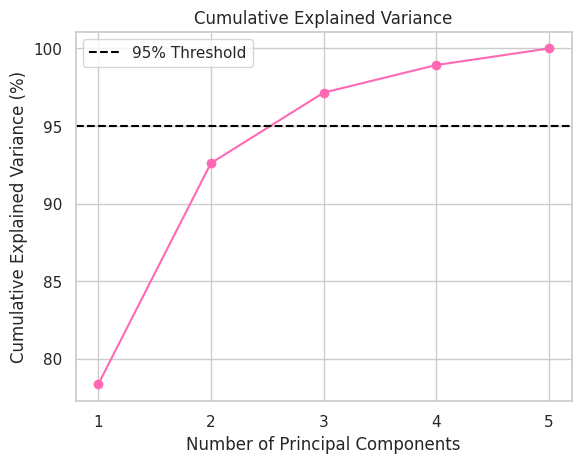

In [35]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.plot(
    range(1, 6),
    cumulative_variance * 100,
    marker='o',
    color='hotpink'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('Cumulative Explained Variance')
plt.xticks(range(1, 6))
plt.grid(True)

plt.axhline(y=95, color='black', linestyle='--', label='95% Threshold')
plt.legend()
plt.show()

In [37]:
# we choose 3 principal components to explain 97.15% of variance
pca3 = PCA(n_components=3)
pca_data = pca3.fit_transform(scaled_data)

In [38]:
pca_data.shape

(398, 3)

In [39]:
# convert pca_data to a panda dataset
pca_df = pd.DataFrame(
    data=pca_data,
    columns=['PC1', 'PC2', 'PC3']
)
pca_df.head()

,PC1,PC2,PC3
0,1.896726,-0.651305,-0.064377
1,2.876977,-0.679411,0.007438
2,2.284997,-1.046847,0.009131
3,2.210385,-0.668947,-0.197021
4,2.208905,-1.148995,-0.237430


# **K-means clustering**

In [40]:
from sklearn.cluster import KMeans

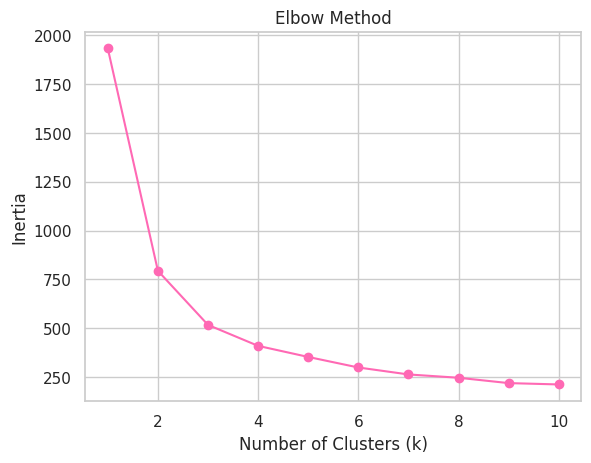

In [41]:
# investigating how many k we need
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(pca_df)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker='o', color='hotpink')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

The elbow method suggests k = 3

In [42]:
# investogate number of k using silhouette method
from sklearn.metrics import silhouette_score

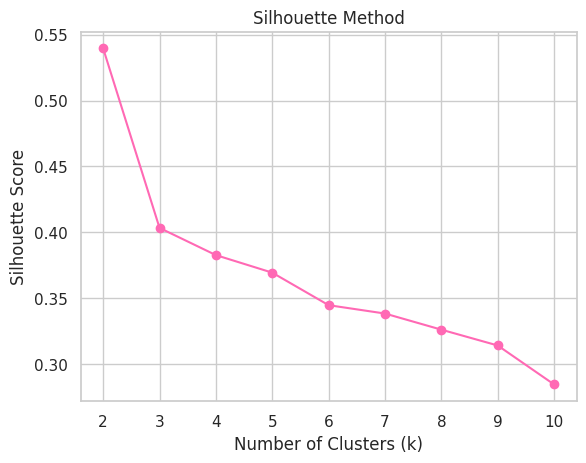

In [46]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(pca_df)
    score = silhouette_score(pca_df, kmeans.labels_)
    silhouette_scores.append(score)

plt.plot(range(2, 11), silhouette_scores,
         marker='o', color='hotpink')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method')
plt.show()

the silhouette method suggest k = 2. we choose k = 2

In [48]:
# create KMeans model with k = 2
kmeans = KMeans(n_clusters=2, random_state= 78)
kmeans.fit(pca_df)
pca_df['Cluster'] = kmeans.predict(pca_df)

In [49]:
pca_df['Cluster'].value_counts()

,count
Cluster,
0,283
1,115


In [50]:
# add cluster lables to original data
df['Cluster'] = pca_df['Cluster']

In [52]:
# comparing average of each cluster
df.groupby('Cluster')[num_cols].mean()

,mpg,displacement,horsepower,weight,acceleration
Cluster,,,,,
0,26.966784,137.192580,84.243167,2530.982332,16.530742
1,15.019130,331.808696,154.243478,4051.834783,13.199130


data devided to two groups: cluster 0 and cluster 1. care in cluster 0 are lighter and have bettre fuel efficiency but lower acceleration and smaller horsepower compare to the cars in cluster 1.

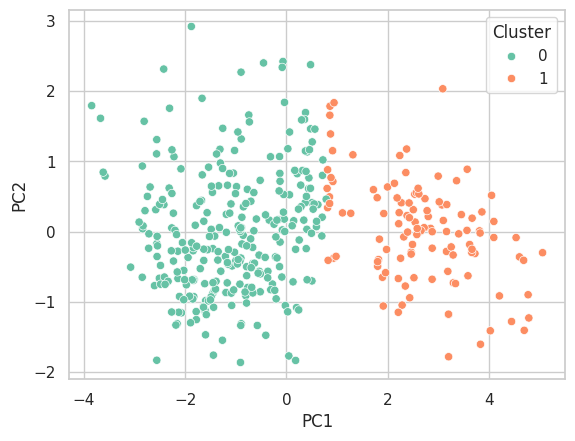

In [53]:
sns.scatterplot(data=pca_df, x='PC1', y='PC2',
                hue='Cluster', palette='Set2')
plt.show()

In [54]:
# examine PCA loadings
pca3.components_

array([[-0.4440547 ,  0.48385965,  0.48345548,  0.47189703, -0.33508097],
       [-0.30820746,  0.13297015, -0.12514622,  0.32367731,  0.87572742],
       [ 0.83768679,  0.3634925 ,  0.22437566,  0.29989669,  0.16084649]])

In [55]:
# convert pca3.components matrix into a panda dataframe
loadings_df = pd.DataFrame(
    data=pca3.components_.T,
    columns=['PC1', 'PC2', 'PC3'],
    index=num_cols
)
loadings_df

,PC1,PC2,PC3
mpg,-0.444055,-0.308207,0.837687
displacement,0.483860,0.132970,0.363492
horsepower,0.483455,-0.125146,0.224376
weight,0.471897,0.323677,0.299897
acceleration,-0.335081,0.875727,0.160846


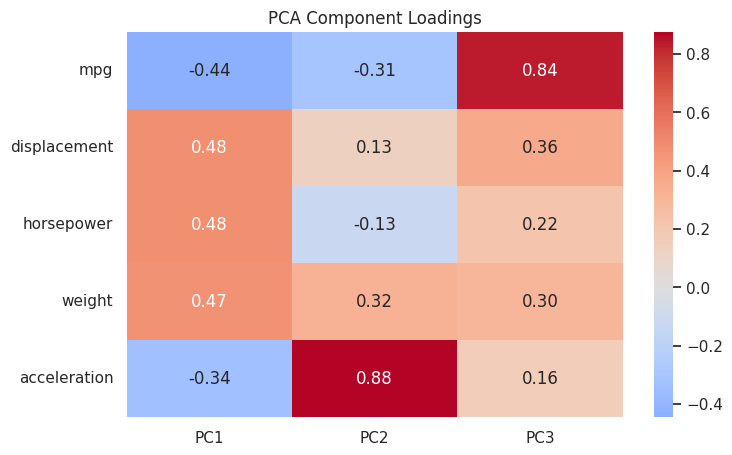

In [57]:
# create a heat map of loading_df
plt.figure(figsize=(8, 5))
sns.heatmap(
    loadings_df,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)
plt.title('PCA Component Loadings')
plt.show()

# **Final Conclusion**
## Final Conclusion

We applied Principal Component Analysis (PCA) to reduce the dimensionality of our dataset from five numerical features to three principal components, retaining approximately **97.15% of the total variance**.

We then used the elbow method and silhouette analysis to determine an appropriate number of clusters. Based on these results, we selected **k = 2**.

Our K-means analysis identified two distinct groups of cars:

- **Cluster 0:** Lighter, more fuel-efficient cars with smaller engines, lower horsepower, and slower acceleration.
- **Cluster 1:** Heavier, more powerful cars with larger engines, faster acceleration, and lower fuel efficiency.

Overall, PCA and K-means successfully revealed meaningful patterns in the dataset, distinguishing cars primarily by their size, power, and fuel efficiency.